# Tim 06 – Analiza skupa podataka APTOS 2019 (Dijabetička retinopatija)
**Neuronske mreže – 2. termin: Podaci i literatura**

Skup podataka: [APTOS 2019 Blindness Detection (Kaggle)](https://www.kaggle.com/competitions/aptos2019-blindness-detection/data)

Oznake (`diagnosis`): 0 – No DR, 1 – Mild, 2 – Moderate, 3 – Severe, 4 – Proliferative DR.

> Napomena: oznake postoje samo za `train.csv` (3662 slike). `test.csv` nema javne oznake, pa train/val/test radimo iz `train.csv`.

## 0. Postavljanje okoline

In [1]:
# !pip install -q imagehash opencv-python-headless seaborn scikit-learn
# Preuzimanje (lokalno / Colab) - treba kaggle.json i prihvatiti pravila natjecanja:
# !kaggle competitions download -c aptos2019-blindness-detection -p data
# !unzip -q data/aptos2019-blindness-detection.zip -d data

In [2]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2
from PIL import Image
import imagehash
from tqdm.auto import tqdm
from sklearn.model_selection import StratifiedGroupKFold

sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)

# Pronađi skup podataka: APTOS_DIR -> Kaggle -> lokalne mape
CANDIDATES = [
    os.environ.get("APTOS_DIR"),
    "/kaggle/input/aptos2019-blindness-detection",
    "aptos2019-blindness-detection",
    "data",
]
DATA_DIR = next((Path(c) for c in CANDIDATES if c and (Path(c) / "train.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(f"Ne nalazim train.csv ni u jednoj od putanja: {CANDIDATES}")
IMG_DIR = DATA_DIR / "train_images"
OUT_DIR = Path("outputs"); OUT_DIR.mkdir(exist_ok=True)

CLASS_NAMES = {0: "No DR", 1: "Mild", 2: "Moderate", 3: "Severe", 4: "Proliferative"}
print(DATA_DIR.resolve(), IMG_DIR.exists())

/Users/antoniosimic/Desktop/nm/aptos2019-blindness-detection True


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Namjena, izvor i veličina skupa

In [3]:
df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv") if (DATA_DIR / "test.csv").exists() else None

df["path"] = df["id_code"].apply(lambda x: IMG_DIR / f"{x}.png")
df["exists"] = df["path"].apply(lambda p: p.exists())

size_gb = sum(p.stat().st_size for p in df["path"] if p.exists()) / 1e9
print(f"Train slika: {len(df)} | postoje na disku: {df['exists'].sum()}")
print(f"Test slika (bez oznaka): {len(test_df) if test_df is not None else 'n/a'}")
print(f"Veličina train_images: {size_gb:.2f} GB")
df.head()

Train slika: 3662 | postoje na disku: 3662
Test slika (bez oznaka): 1928
Veličina train_images: 8.60 GB


,id_code,diagnosis,path,exists
0,000c1434d8d7,2,aptos2019-blindness-detection/train_images/000...,True
1,001639a390f0,4,aptos2019-blindness-detection/train_images/001...,True
2,0024cdab0c1e,1,aptos2019-blindness-detection/train_images/002...,True
3,002c21358ce6,0,aptos2019-blindness-detection/train_images/002...,True
4,005b95c28852,0,aptos2019-blindness-detection/train_images/005...,True


## 2. Distribucija oznaka

,klasa,broj,%
0,No DR,1805,49.3
1,Mild,370,10.1
2,Moderate,999,27.3
3,Severe,193,5.3
4,Proliferative,295,8.1


Omjer neuravnoteženosti (max/min): 9.4


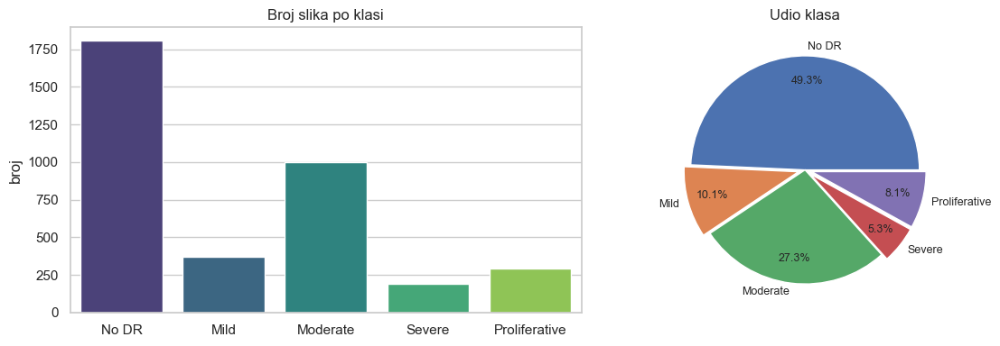

No DR vs DR: 1805 1857


In [4]:
counts = df["diagnosis"].value_counts().sort_index()
pct = (counts / counts.sum() * 100).round(1)
display(pd.DataFrame({"klasa": [CLASS_NAMES[i] for i in counts.index], "broj": counts.values, "%": pct.values}))
print(f"Omjer neuravnoteženosti (max/min): {counts.max() / counts.min():.1f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(x=[CLASS_NAMES[i] for i in counts.index], y=counts.values,
            hue=[CLASS_NAMES[i] for i in counts.index], legend=False, ax=ax[0], palette="viridis")
ax[0].set_title("Broj slika po klasi"); ax[0].set_ylabel("broj")
ax[1].pie(counts.values, labels=[CLASS_NAMES[i] for i in counts.index], autopct="%1.1f%%",
          pctdistance=0.78, labeldistance=1.08,
          explode=[0.06 if v / counts.sum() < 0.12 else 0 for v in counts.values],
          textprops={"fontsize": 9})
ax[1].set_title("Udio klasa")
plt.tight_layout(); plt.savefig(OUT_DIR / "label_dist.png", dpi=150); plt.show()

# binarno: DR vs no DR
print("No DR vs DR:", (df.diagnosis == 0).sum(), (df.diagnosis > 0).sum())

## 3. Prikaz primjera po klasama

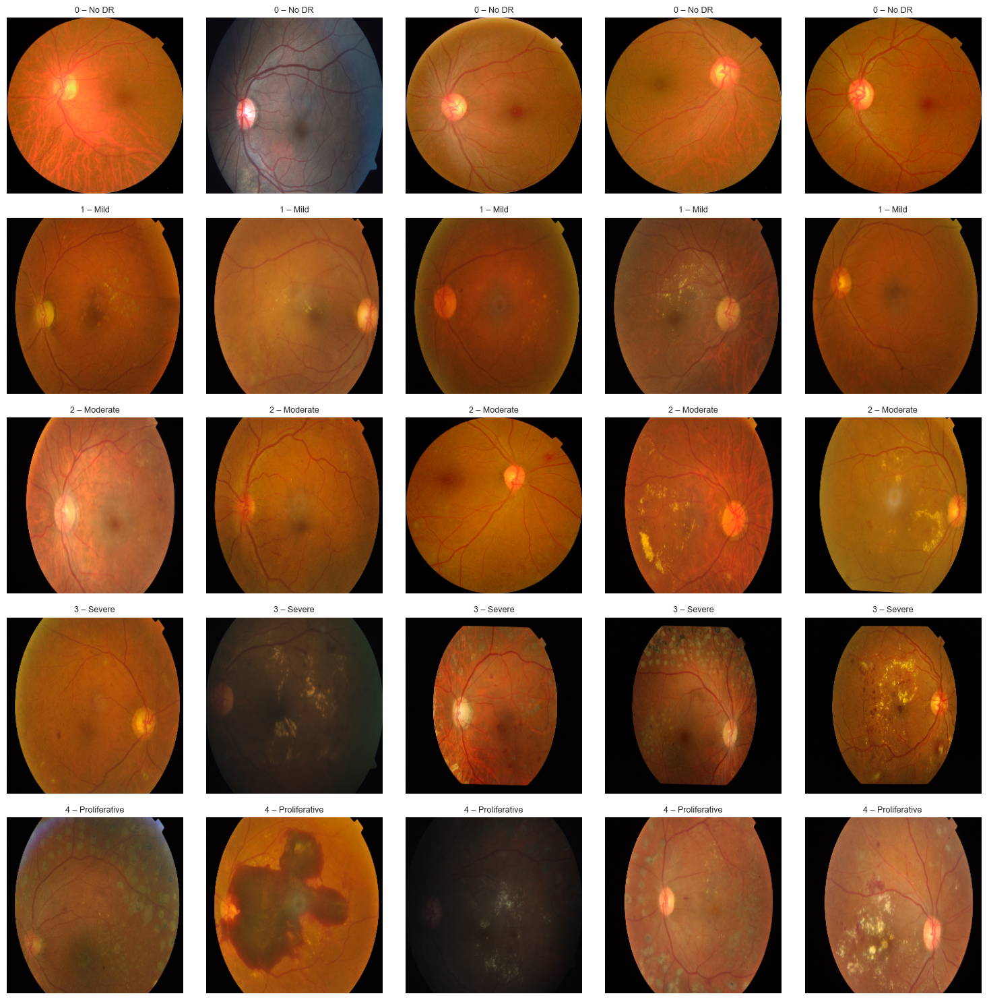

In [5]:
def load_rgb(p, size=None):
    img = cv2.imread(str(p))
    if img is None:
        raise FileNotFoundError(f"Ne mogu pročitati sliku: {p}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    return cv2.resize(img, (size, size)) if size else img

N = 5
fig, axes = plt.subplots(5, N, figsize=(3 * N, 15))
for c in range(5):
    sample = df[df.diagnosis == c].sample(min(N, (df.diagnosis == c).sum()), random_state=SEED)
    for j, (_, r) in enumerate(sample.iterrows()):
        axes[c, j].imshow(load_rgb(r.path, 256)); axes[c, j].axis("off")
        axes[c, j].set_title(f"{c} – {CLASS_NAMES[c]}", fontsize=9)
plt.tight_layout(); plt.savefig(OUT_DIR / "samples_per_class.png", dpi=120); plt.show()


## 4. Značajke slika i osnovna statistika
Za svaku sliku računamo: dimenzije, veličinu datoteke, srednji intenzitet i std po kanalu,
oštrinu (varijanca Laplaciana), udio tamne pozadine i perceptualni hash (za duplikate).
Rezultat se sprema u `outputs/image_stats.csv` da se ne računa ponovno.

In [6]:
def image_stats(p):
    with Image.open(p) as im:
        w, h = im.size
        ph = str(imagehash.phash(im))
    img = cv2.imread(str(p), cv2.IMREAD_REDUCED_COLOR_4)  # 4x manje = brže
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    mask = gray > 10                                         # piksel unutar oka
    b, g, r = [img[..., i][mask] for i in range(3)]
    return dict(
        width=w, height=h, aspect=w / h, file_kb=p.stat().st_size / 1024,
        mean_r=r.mean(), mean_g=g.mean(), mean_b=b.mean(),
        std_gray=gray[mask].std(),                            # kontrast
        brightness=gray[mask].mean(),
        sharpness=cv2.Laplacian(gray, cv2.CV_64F).var(),
        # oštrina mjerena NAKON svođenja na jedinstvenu veličinu -> neovisna o rezoluciji izvornika.
        # Sirova 'sharpness' korelira s 'width' na -0.86, pa sama po sebi mjeri rezoluciju, a ne zamućenost.
        sharpness_norm=cv2.Laplacian(cv2.resize(gray, (512, 512)), cv2.CV_64F).var(),
        black_frac=1 - mask.mean(),                           # udio tamnog ruba
        phash=ph,
    )

cache = OUT_DIR / "image_stats.csv"
if cache.exists():
    stats = pd.read_csv(cache)
else:
    stats = pd.DataFrame([image_stats(p) for p in tqdm(df.path)])
    stats.insert(0, "id_code", df.id_code.values)
    stats.to_csv(cache, index=False)

data = df.merge(stats, on="id_code")
NUM = ["width", "height", "aspect", "file_kb", "brightness", "std_gray", "sharpness",
       "sharpness_norm", "black_frac", "mean_r", "mean_g", "mean_b"]
data[NUM].describe().T.assign(median=data[NUM].median()).round(2)

,count,mean,std,min,25%,50%,75%,max,median
width,3662.0,2015.18,884.30,474.00,1050.00,2144.00,2588.00,4288.00,2144.00
height,3662.0,1526.83,542.66,358.00,1050.00,1536.00,1958.00,2848.00,1536.00
aspect,3662.0,1.28,0.18,1.00,1.00,1.33,1.39,1.51,1.33
file_kb,3662.0,2294.22,1721.14,216.54,980.46,1889.60,2780.13,7494.43,1889.60
brightness,3662.0,87.70,20.79,27.65,73.75,91.07,102.66,155.82,91.07
std_gray,3662.0,17.61,5.76,5.88,13.81,16.56,19.95,55.84,16.56
sharpness,3662.0,145.41,127.99,9.08,46.07,85.90,259.92,1413.78,85.90
sharpness_norm,3662.0,29.53,19.75,1.86,16.36,22.25,41.15,162.07,22.25
black_frac,3662.0,0.23,0.13,0.00,0.17,0.21,0.25,0.53,0.21
mean_r,3662.0,138.72,35.92,34.87,117.24,146.49,165.34,237.81,146.49


In [7]:
# statistika po klasama
data.groupby("diagnosis")[["width", "height", "brightness", "std_gray", "sharpness", "black_frac"]].agg(["mean", "median", "std"]).round(1)

width                 height                brightness         \
             mean  median    std    mean  median    std       mean median   
diagnosis                                                                   
0          1433.4  1050.0  629.4  1206.7  1050.0  407.2       90.0   96.5   
1          2471.4  2416.0  625.8  1784.7  1736.0  395.2       84.6   82.6   
2          2603.9  2588.0  735.2  1846.5  1958.0  493.2       86.9   87.5   
3          2590.7  2588.0  603.3  1840.8  1944.0  398.9       81.8   83.0   
4          2632.3  2588.0  791.0  1874.5  1958.0  527.2       83.9   85.8   

                std_gray             sharpness               black_frac  \
            std     mean median  std      mean median    std       mean   
diagnosis                                                                 
0          21.1     19.2   18.0  5.4     221.4  254.2  135.0        0.3   
1          17.3     15.4   14.1  5.1      78.0   67.1   53.5        0.2   
2          21.5     15.9   14.6  5.7      71.6   53.4   65.9        0.2   
3          19.9     18.0   16.2  6.4      62.7   55.0   40.4        0.2   
4          19.4     16.4   14.9  5.6      69.1   58.3   52.6        0.2   

                       
          median  std  
diagnosis              
0            0.2  0.2  
1            0.2  0.1  
2            0.2  0.1  
3            0.2  0.1  
4            0.2  0.1

## 5. Rezolucije i mogućnost curenja podataka (*shortcut learning*)

Broj različitih rezolucija: 17


res
1050x1050    974
2416x1736    638
2588x1958    533
3216x2136    410
2048x1536    351
819x614      287
3388x2588    141
1504x1000     92
1844x1226     61
4288x2848     52
Name: count, dtype: int64

/var/folders/3b/hndgw4v14292vhfmzs9pmv5c0000gn/T/ipykernel_88207/3508614487.py:7: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  ct_norm = ct.div(ct.sum(1), axis=0)


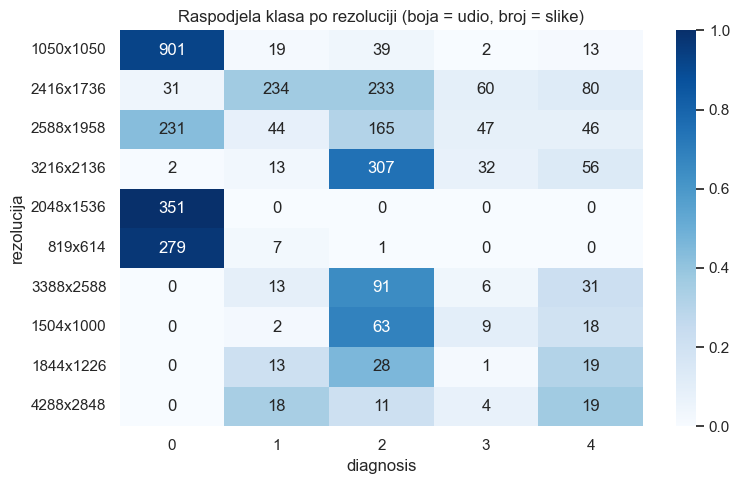

In [8]:
data["res"] = data.width.astype(str) + "x" + data.height.astype(str)
top_res = data.res.value_counts().head(10)
print("Broj različitih rezolucija:", data.res.nunique())
display(top_res)

ct = pd.crosstab(data.res, data.diagnosis).loc[top_res.index]
ct_norm = ct.div(ct.sum(1), axis=0)
plt.figure(figsize=(8, 5))
sns.heatmap(ct_norm, annot=ct.values, fmt="d", cmap="Blues")
plt.title("Raspodjela klasa po rezoluciji (boja = udio, broj = slike)")
plt.xlabel("diagnosis"); plt.ylabel("rezolucija")
plt.tight_layout(); plt.savefig(OUT_DIR / "res_vs_class.png", dpi=150); plt.show()
# Ako je rezolucija jako povezana s klasom, model može učiti izvor kamere umjesto bolesti
# -> zato sve slike resizeamo na istu veličinu i radimo crop rubova.

## 6. Distribucije značajki po klasama i odnosi između značajki

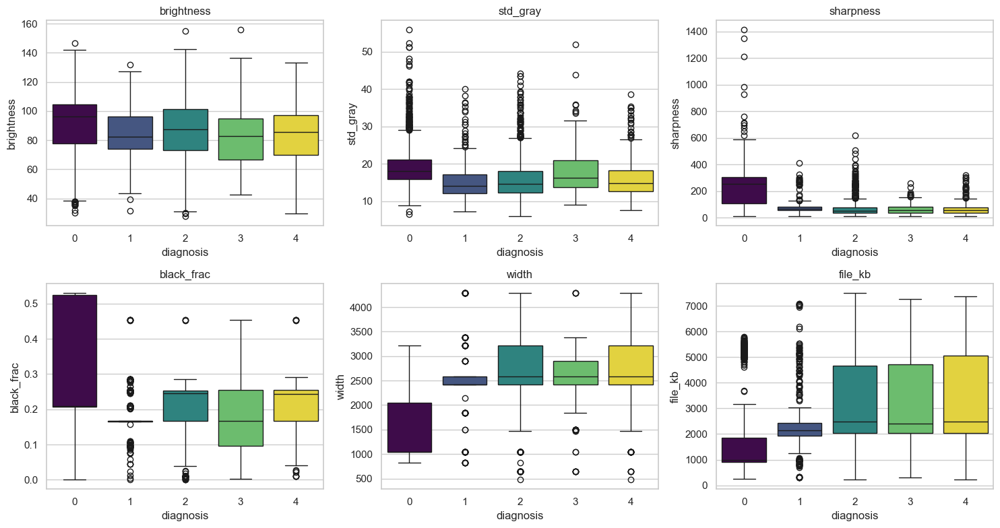

In [9]:
feats = ["brightness", "std_gray", "sharpness", "black_frac", "width", "file_kb"]
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, f in zip(axes.ravel(), feats):
    sns.boxplot(data=data, x="diagnosis", y=f, hue="diagnosis", legend=False, ax=ax, palette="viridis")
    ax.set_title(f)
plt.tight_layout(); plt.savefig(OUT_DIR / "feat_by_class.png", dpi=150); plt.show()

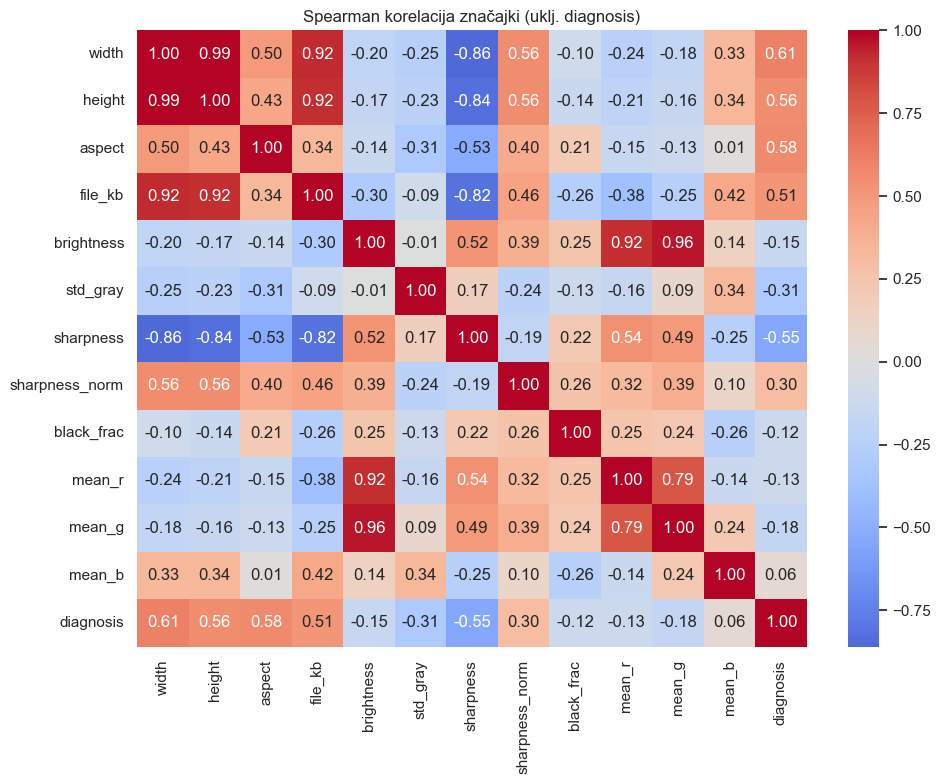

In [10]:
corr = data[NUM + ["diagnosis"]].corr(method="spearman")
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman korelacija značajki (uklj. diagnosis)")
plt.tight_layout(); plt.savefig(OUT_DIR / "corr.png", dpi=150); plt.show()

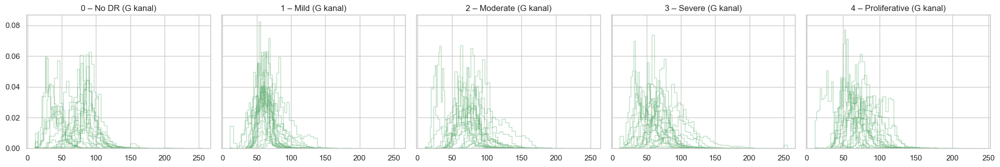

In [11]:
# histogrami intenziteta po kanalima (unutar oka) za nekoliko slika po klasi
fig, axes = plt.subplots(1, 5, figsize=(20, 3.5), sharey=True)
for c, ax in enumerate(axes):
    for _, r in data[data.diagnosis == c].sample(min(20, (data.diagnosis == c).sum()), random_state=SEED).iterrows():
        img = cv2.imread(str(r.path), cv2.IMREAD_REDUCED_COLOR_8)
        g = img[..., 1]; g = g[g > 10]
        ax.hist(g, bins=50, histtype="step", alpha=.4, density=True, color="g")
    ax.set_title(f"{c} – {CLASS_NAMES[c]} (G kanal)")
plt.tight_layout(); plt.show()

## 7. Potencijalni problemi: nedostajuće vrijednosti, stršeće vrijednosti, duplikati

In [12]:
print("Nedostajuće vrijednosti u CSV-u:\n", df[["id_code", "diagnosis"]].isna().sum())
print("Nepostojeće slike:", (~df.exists).sum())
print("Duplicirani id_code:", df.id_code.duplicated().sum())

def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return (s < q1 - k * i) | (s > q3 + k * i)

for f in ["brightness", "std_gray", "sharpness_norm"]:
    print(f"Outlieri ({f}): {iqr_outliers(data[f]).sum()}")

Nedostajuće vrijednosti u CSV-u:
 id_code      0
diagnosis    0
dtype: int64
Nepostojeće slike: 0
Duplicirani id_code: 0
Outlieri (brightness): 8
Outlieri (std_gray): 175
Outlieri (sharpness_norm): 94


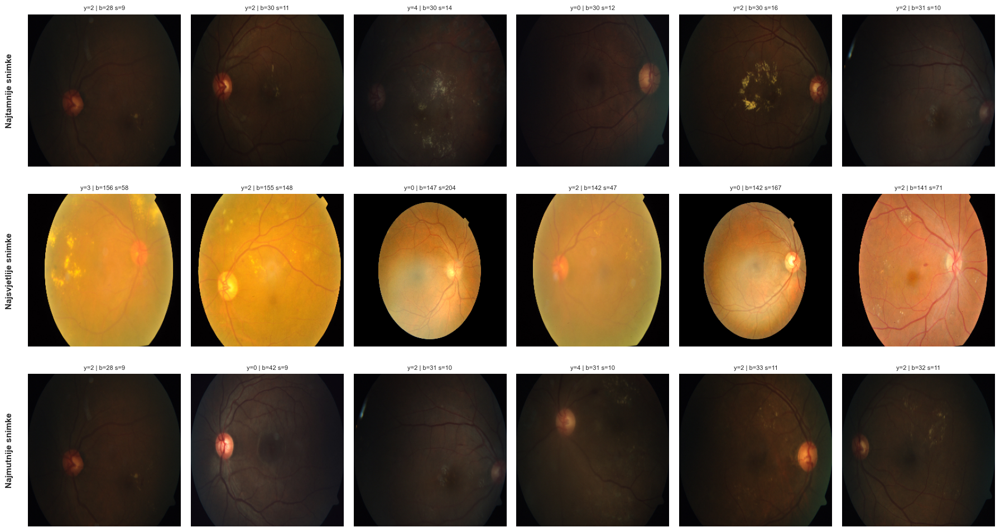

In [13]:
# Najtamnije / najsvjetlije / najmutnije snimke - jedna složena slika za izvještaj
def show(rows, title, save=None):
    rows = rows if hasattr(rows, "iterrows") else rows
    fig, axes = plt.subplots(1, len(rows), figsize=(3 * len(rows), 3.3))
    for ax, (_, r) in zip(np.atleast_1d(axes), rows.iterrows()):
        ax.imshow(load_rgb(r.path, 256)); ax.axis("off")
        ax.set_title(f"y={r.diagnosis} | b={r.brightness:.0f} s={r.sharpness:.0f}", fontsize=8)
    fig.suptitle(title); plt.tight_layout()
    if save: plt.savefig(OUT_DIR / save, dpi=130, bbox_inches="tight")
    plt.show()

# složena slika 3x6 za izvještaj (tamne / svijetle / mutne)
GROUPS = [("Najtamnije snimke", data.nsmallest(6, "brightness")),
          ("Najsvjetlije snimke", data.nlargest(6, "brightness")),
          ("Najmutnije snimke", data.nsmallest(6, "sharpness"))]
fig, axes = plt.subplots(3, 6, figsize=(18, 10))
for row, (name, rows) in enumerate(GROUPS):
    for col, (_, r) in enumerate(rows.iterrows()):
        axes[row, col].imshow(load_rgb(r.path, 256)); axes[row, col].axis("off")
        axes[row, col].set_title(f"y={r.diagnosis} | b={r.brightness:.0f} s={r.sharpness:.0f}", fontsize=8)
    axes[row, 0].text(-0.12, 0.5, name, transform=axes[row, 0].transAxes,
                      rotation=90, va="center", ha="center", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.savefig(OUT_DIR / "outliers.png", dpi=120, bbox_inches="tight"); plt.show()


### Opravdanje praga za detekciju duplikata

Fundus snimke su strukturno vrlo slične (krug mrežnice na crnoj pozadini, svijetla papila), pa labav
prag perceptualnog hasha spaja **različita oka**. Uz `union-find` to se lančano širi: A~B, B~C povezuje
i A i C. Zato prag biramo mjerenjem, a ne pretpostavkom.

In [14]:
# Duplikati preko perceptualnog hasha (phash), spajanje union-findom.
# IZBOR PRAGA: vidi sljedeću ćeliju - prag 0 (identičan hash) jedini daje stvarne duplikate.
# Pri pragu 4 lančano spajanje stvara grupu od 187 slika, što su različita oka sa
# sličnom grubom strukturom (krug mrežnice, svijetla papila), a ne duplikati.
THR = 0

H = np.array([imagehash.hex_to_hash(h).hash.flatten() for h in data.phash], dtype=np.uint8)
n = len(H)
parent = list(range(n))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i

for i in tqdm(range(n)):
    d = (H[i + 1:] != H[i]).sum(1)
    for j in np.where(d <= THR)[0] + i + 1:
        parent[find(j)] = find(i)

# ID grupe = indeks korijena union-finda; preslikavamo u uredne redne brojeve 0..k-1
_roots = [find(i) for i in range(n)]
_renum = {r: k for k, r in enumerate(dict.fromkeys(_roots))}
data["dup_group"] = [_renum[r] for r in _roots]
grp = data.groupby("dup_group")
sizes = grp.size()
dup_groups = sizes[sizes > 1].index
conflict = grp.diagnosis.nunique()
print(f"Grupa duplikata: {len(dup_groups)} | slika u njima: {sizes[sizes > 1].sum()}")
print(f"Najveća grupa: {sizes.max()} slika")
print(f"Grupa s KONFLIKTNIM oznakama: {(conflict[dup_groups] > 1).sum()}")


  0%|          | 0/3662 [00:00<?, ?it/s]

 60%|██████    | 2206/3662 [00:00<00:00, 22058.02it/s]

100%|██████████| 3662/3662 [00:00<00:00, 29563.28it/s]

Grupa duplikata: 143 | slika u njima: 295
Najveća grupa: 4 slika
Grupa s KONFLIKTNIM oznakama: 38


In [15]:
# Provjera izbora praga: veličine grupa + pikselska potvrda da su to doista isti snimci
def _groups(thr):
    par = list(range(n))
    def f(i):
        while par[i] != i: par[i] = par[par[i]]; i = par[i]
        return i
    for i in range(n):
        dd = (H[i + 1:] != H[i]).sum(1)
        for j in np.where(dd <= thr)[0] + i + 1: par[f(j)] = f(i)
    return pd.Series([f(i) for i in range(n)], index=data.index)

print("prag | grupa>1 | slika u njima | najveća grupa | konfliktnih grupa")
for thr in [0, 2, 4]:
    g = _groups(thr); sz = g.value_counts(); multi = sz[sz > 1]
    conf = data.assign(_g=g).groupby("_g").diagnosis.nunique()
    print(f"  {thr}  |  {len(multi):4d}   |    {multi.sum():5d}      |     {sz.max():4d}      |      "
          f"{(conf[multi.index] > 1).sum():4d}")

# Pikselska potvrda: koliko se snimke unutar grupe doista razlikuju (sivi thumbnail 64x64)
def _thumb(idc):
    im = cv2.imread(str(IMG_DIR / f"{idc}.png"), cv2.IMREAD_GRAYSCALE)
    return cv2.resize(im, (64, 64)).astype(np.float32)

rng = np.random.default_rng(1)
_sample = rng.choice(dup_groups, min(40, len(dup_groups)), replace=False)
_in = [np.abs(a - b).mean()
       for g in _sample
       for ts in [[_thumb(i) for i in data[data.dup_group == g].id_code]]
       for ai, a in enumerate(ts) for b in ts[ai + 1:]]
_ridx = rng.choice(n, 60, replace=False)
_rt = [_thumb(data.id_code.iloc[i]) for i in _ridx]
_out = [np.abs(_rt[a] - _rt[b]).mean() for a in range(len(_rt)) for b in range(a + 1, len(_rt))]
print(f"\nSrednja pikselska razlika UNUTAR grupa duplikata: medijan {np.median(_in):.1f}")
print(f"Srednja pikselska razlika nasumičnih parova:        medijan {np.median(_out):.1f}")
print("-> razlika blizu nule potvrđuje da su to isti snimci, a ne tek slična oka.")


prag | grupa>1 | slika u njima | najveća grupa | konfliktnih grupa
  0  |   143   |      295      |        4      |        38


  2  |   220   |      581      |       27      |        61
  4  |   255   |     1414      |      187      |        95



Srednja pikselska razlika UNUTAR grupa duplikata: medijan 0.0
Srednja pikselska razlika nasumičnih parova:        medijan 33.9
-> razlika blizu nule potvrđuje da su to isti snimci, a ne tek slična oka.


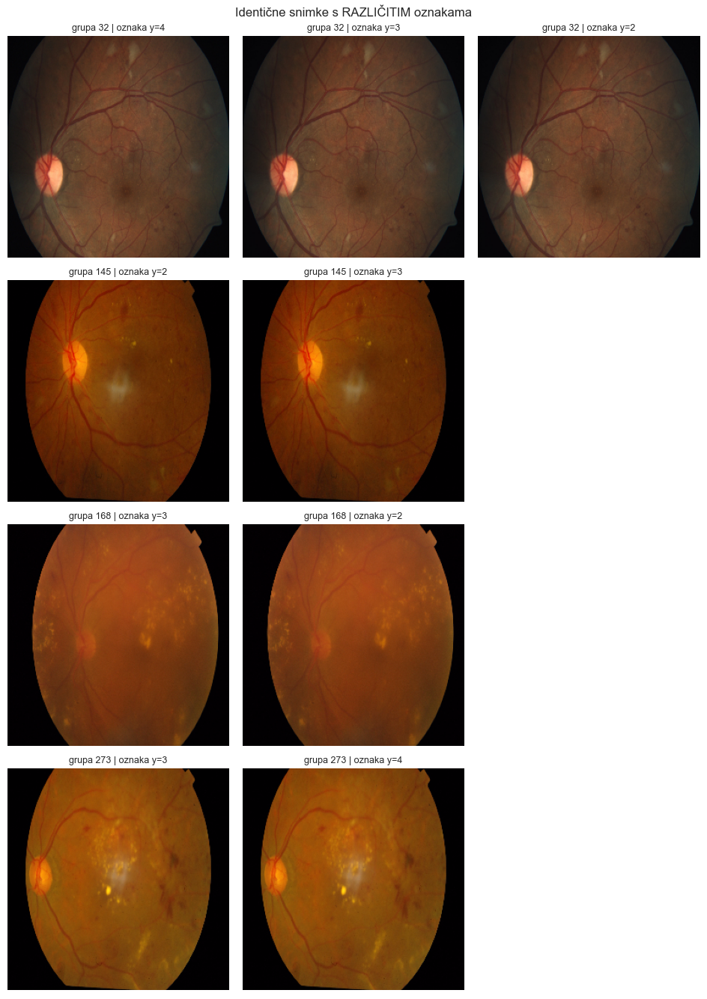

In [16]:
# Primjeri duplikata s različitim oznakama -> dokaz šuma u oznakama
bad = conflict[conflict > 1].index[:4]
if len(bad):
    rows_all = pd.concat([data[data.dup_group == g].head(3) for g in bad])
    ncol = 3
    fig, axes = plt.subplots(len(bad), ncol, figsize=(3.2 * ncol, 3.4 * len(bad)), squeeze=False)
    for ri, g in enumerate(bad):
        grp_rows = data[data.dup_group == g].head(ncol)
        for ci in range(ncol):
            ax = axes[ri, ci]; ax.axis("off")
            if ci < len(grp_rows):
                r = grp_rows.iloc[ci]
                ax.imshow(load_rgb(r.path, 256))
                ax.set_title(f"grupa {g} | oznaka y={r.diagnosis}", fontsize=9)
    fig.suptitle("Identične snimke s RAZLIČITIM oznakama", fontsize=12)
    plt.tight_layout(); plt.savefig(OUT_DIR / "dup_conflict.png", dpi=120, bbox_inches="tight"); plt.show()
else:
    print("Nema grupa duplikata s konfliktnim oznakama.")


## 8. Metode predobrade (Varijanta 2)
Obrezivanje tamnih rubova, Histogram Equalization, CLAHE i (za usporedbu) Ben Graham metoda.

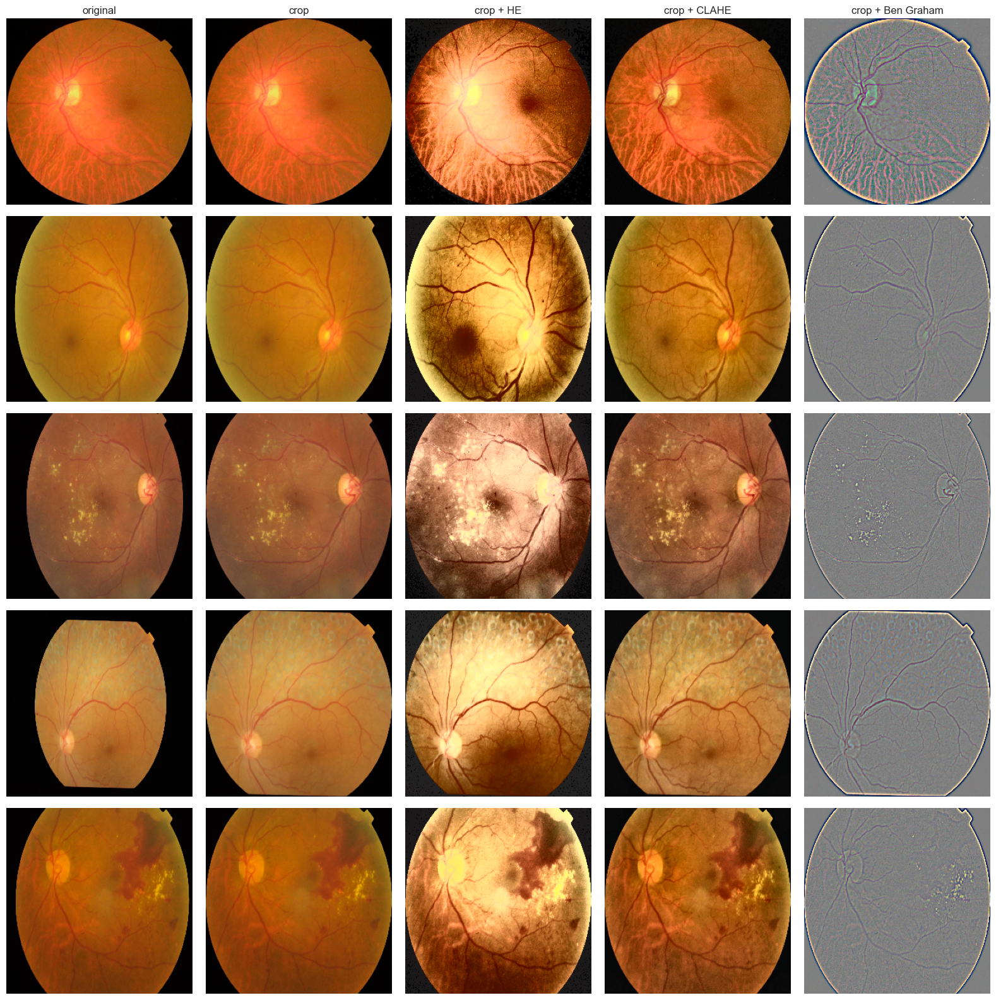

In [17]:
def crop_black(img, tol=10):
    gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    m = gray > tol
    if not m.any():
        return img
    ys, xs = np.where(m)
    return img[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

def hist_eq(img):
    ycc = cv2.cvtColor(img, cv2.COLOR_RGB2YCrCb)
    ycc[..., 0] = cv2.equalizeHist(ycc[..., 0])
    return cv2.cvtColor(ycc, cv2.COLOR_YCrCb2RGB)

def clahe(img, clip=2.0, tile=8):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    lab[..., 0] = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(lab[..., 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

def ben_graham(img, sigma=10):
    return cv2.addWeighted(img, 4, cv2.GaussianBlur(img, (0, 0), sigma), -4, 128)

PIPE = {
    "original": lambda x: x,
    "crop": crop_black,
    "crop + HE": lambda x: hist_eq(crop_black(x)),
    "crop + CLAHE": lambda x: clahe(crop_black(x)),
    "crop + Ben Graham": lambda x: ben_graham(crop_black(x)),
}

rows = data.groupby("diagnosis").sample(1, random_state=SEED)
fig, axes = plt.subplots(len(rows), len(PIPE), figsize=(3.2 * len(PIPE), 3.2 * len(rows)))
for i, (_, r) in enumerate(rows.iterrows()):
    img = load_rgb(r.path)
    for j, (name, f) in enumerate(PIPE.items()):
        axes[i, j].imshow(cv2.resize(f(img), (256, 256))); axes[i, j].axis("off")
        if i == 0: axes[i, j].set_title(name)
    axes[i, 0].set_ylabel(CLASS_NAMES[r.diagnosis])
plt.tight_layout(); plt.savefig(OUT_DIR / "preprocessing.png", dpi=120); plt.show()

In [18]:
# Učinak predobrade na kontrast (std unutar oka) - na uzorku slika
sub = data.sample(min(200, len(data)), random_state=SEED)
res = {k: [] for k in PIPE}
for p in tqdm(sub.path):
    img = cv2.resize(load_rgb(p), (512, 512))
    for k, f in PIPE.items():
        g = cv2.cvtColor(cv2.resize(f(img), (512, 512)), cv2.COLOR_RGB2GRAY)
        res[k].append(g[g > 10].std())
pd.DataFrame(res).describe().T[["mean", "50%", "std"]].round(1)

  0%|          | 0/200 [00:00<?, ?it/s]

  1%|          | 2/200 [00:00<00:10, 19.25it/s]

  2%|▏         | 4/200 [00:00<00:12, 16.15it/s]

  4%|▍         | 8/200 [00:00<00:10, 18.87it/s]

  5%|▌         | 10/200 [00:00<00:11, 16.79it/s]

  6%|▋         | 13/200 [00:00<00:10, 17.81it/s]

... (52 outputs left out)

 97%|█████████▋| 194/200 [00:08<00:00, 24.97it/s]

 99%|█████████▉| 198/200 [00:08<00:00, 24.53it/s]

100%|██████████| 200/200 [00:08<00:00, 23.44it/s]

,mean,50%,std
original,18.0,17.1,5.6
crop,18.1,17.2,5.6
crop + HE,67.8,67.6,1.8
crop + CLAHE,24.5,24.0,5.3
crop + Ben Graham,29.9,31.2,5.3


## 9. Podjela na train / val / test
Stratificirano po `diagnosis` i **grupirano po `dup_group`** – duplikati iste slike moraju biti u istom skupu,
inače dolazi do curenja podataka. Omjer ≈ 70 / 15 / 15.

split
train    2615
test      524
val       523
Name: count, dtype: int64
Grupa u više skupova: 0


diagnosis,0,1,2,3,4
split,,,,,
test,0.492,0.101,0.273,0.052,0.082
train,0.493,0.101,0.273,0.053,0.080
val,0.493,0.101,0.272,0.054,0.080


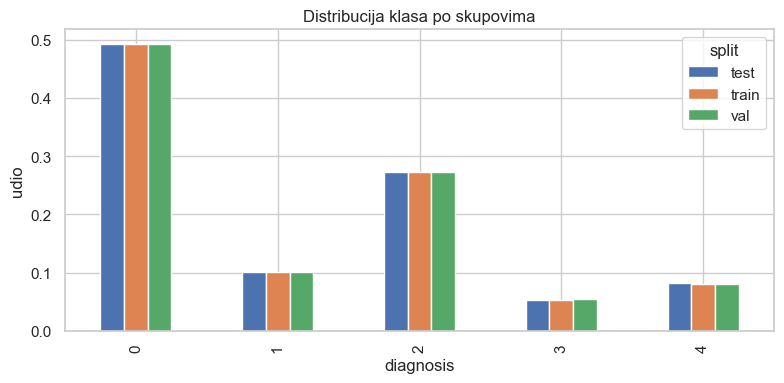

In [19]:
def group_split(d, n_splits, seed=SEED):
    sgkf = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    a, b = next(sgkf.split(d, d.diagnosis, d.dup_group))
    return d.iloc[a], d.iloc[b]

trainval, test = group_split(data, n_splits=7)          # ~15 % test
train, val = group_split(trainval, n_splits=6)          # ~15 % od ukupnog za val

split = pd.concat([train.assign(split="train"), val.assign(split="val"), test.assign(split="test")])
print(split.split.value_counts())

# provjera curenja: nijedna dup_group u više skupova
leak = split.groupby("dup_group").split.nunique()
print("Grupa u više skupova:", (leak > 1).sum())

dist = pd.crosstab(split.split, split.diagnosis, normalize="index").round(3)
display(dist)
dist.T.plot.bar(figsize=(8, 4)); plt.title("Distribucija klasa po skupovima"); plt.ylabel("udio")
plt.tight_layout(); plt.savefig(OUT_DIR / "split_dist.png", dpi=150); plt.show()

split[["id_code", "diagnosis", "dup_group", "split"]].to_csv(OUT_DIR / "split.csv", index=False)

In [20]:
# Težine klasa za loss (za rješavanje disbalansa, Varijanta 2)
cnt = train.diagnosis.value_counts().sort_index()
class_w = (len(train) / (len(cnt) * cnt)).round(3)
class_w

diagnosis
0    0.406
1    1.981
2    0.732
3    3.790
4    2.490
Name: count, dtype: float64

## 10. "Laki" i "teški" primjeri
- **Laki**: oštre, dobro osvijetljene slike klase 0 (zdravo oko) i klase 4 (proliferativna – jasne promjene, krvarenja, novostvorene žile).
- **Teški**: klasa 1 (Mild – samo sitne mikroaneurizme, lako se zamijeni s 0), granice 2↔3, te slike lošije kvalitete (tamne, mutne) bilo koje klase.

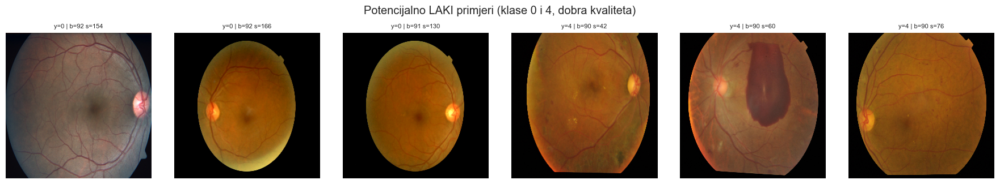

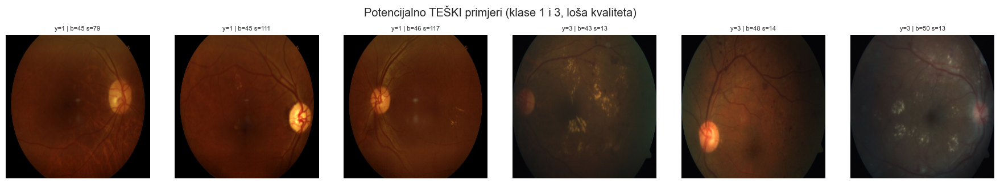

In [21]:
q = data.copy()
# Kompozitna ocjena kvalitete: percentilni rang normalizirane oštrine + blizina srednjoj svjetlini.
# Koristimo sharpness_norm (mjerenu na 512x512) jer sirova oštrina mjeri rezoluciju, ne zamućenost.
# Svjetlinu kažnjavamo dvosmjerno: i pretamne i presvijetle snimke su loše, pa rang ne bi valjao.
_b = q.brightness
q["quality"] = (q.sharpness_norm.rank(pct=True)
                + (1 - (_b - _b.median()).abs().rank(pct=True))) / 2

easy = pd.concat([q[q.diagnosis == 0].nlargest(3, "quality"), q[q.diagnosis == 4].nlargest(3, "quality")])
hard = pd.concat([q[q.diagnosis == 1].nsmallest(3, "quality"), q[q.diagnosis == 3].nsmallest(3, "quality")])
show(easy, "Potencijalno LAKI primjeri (klase 0 i 4, dobra kvaliteta)", save="easy.png")
show(hard, "Potencijalno TEŠKI primjeri (klase 1 i 3, loša kvaliteta)", save="hard.png")

In [22]:
# Kvaliteta po klasama - koliko 'loših' slika ima u svakoj klasi
q["low_quality"] = q.quality < q.quality.quantile(0.1)
q.groupby("diagnosis").low_quality.mean().round(3).rename("udio slika loše kvalitete")

diagnosis
0    0.116
1    0.059
2    0.089
3    0.093
4    0.098
Name: udio slika loše kvalitete, dtype: float64

In [23]:
# Izvoz svih ključnih brojeva u JSON -> koristi se za popunjavanje izvještaja
import json as _json

_counts = df["diagnosis"].value_counts().sort_index()
_desc = data[NUM].describe().T
_stats = {
    "n_train_csv": int(len(df)),
    "n_images_on_disk": int(df["exists"].sum()),
    "n_test_unlabeled": int(len(test_df)) if test_df is not None else None,
    "size_gb": round(float(size_gb), 2),
    "class_counts": {CLASS_NAMES[int(k)]: int(v) for k, v in _counts.items()},
    "class_pct": {CLASS_NAMES[int(k)]: round(float(v) / len(df) * 100, 1) for k, v in _counts.items()},
    "imbalance_ratio": round(float(_counts.max() / _counts.min()), 1),
    "n_no_dr": int((df.diagnosis == 0).sum()),
    "n_dr": int((df.diagnosis > 0).sum()),
    "corr_with_diagnosis": {f: round(float(data[NUM + ["diagnosis"]].corr(method="spearman")
                                                 .loc[f, "diagnosis"]), 3) for f in NUM},
    "corr_sharp_width": round(float(data[["sharpness", "width"]].corr(method="spearman").iloc[0, 1]), 3),
    "n_referral": int((df.diagnosis >= 2).sum()),
    "n_no_referral": int((df.diagnosis < 2).sum()),
    "n_resolutions": int(data.res.nunique()),
    "top_resolutions": {str(k): int(v) for k, v in data.res.value_counts().head(5).items()},
    "res_class_dist": {
        str(r): {CLASS_NAMES[int(c)]: round(float(v), 3) for c, v in
                 (data[data.res == r].diagnosis.value_counts(normalize=True).sort_index()).items()}
        for r in data.res.value_counts().head(5).index
    },
    "overall_class_frac": {CLASS_NAMES[int(k)]: round(float(v), 3)
                            for k, v in df.diagnosis.value_counts(normalize=True).sort_index().items()},
    "n_missing_labels": int(df[["id_code", "diagnosis"]].isna().sum().sum()),
    "n_missing_images": int((~df.exists).sum()),
    "n_dup_id": int(df.id_code.duplicated().sum()),
    "n_dup_groups": int(len(dup_groups)),
    "n_images_in_dup_groups": int(sizes[sizes > 1].sum()),
    "n_conflicting_dup_groups": int((conflict > 1).sum()),
    "dup_threshold": int(THR),
    "max_dup_group": int(sizes.max()),
    "dup_px_diff_in": round(float(np.median(_in)), 1),
    "dup_px_diff_rand": round(float(np.median(_out)), 1),
    "outliers": {f: int(iqr_outliers(data[f]).sum()) for f in ["brightness", "std_gray", "sharpness_norm"]},
    "numeric_stats": {
        f: {k: round(float(_desc.loc[f, k]), 2) for k in ["mean", "std", "min", "50%", "max"]}
        for f in NUM
    },
    "split_sizes": {k: int(v) for k, v in split.split.value_counts().items()},
    "split_class_dist": {s: {CLASS_NAMES[int(c)]: round(float(dist.loc[s, c]), 3) for c in dist.columns}
                          for s in dist.index},
    "leaked_groups": int((leak > 1).sum()),
    "class_weights": {CLASS_NAMES[int(k)]: float(v) for k, v in class_w.items()},
    "preproc_contrast": {k: {"mean": round(float(np.mean(v)), 1),
                              "median": round(float(np.median(v)), 1),
                              "std": round(float(np.std(v)), 1)} for k, v in res.items()},
    "low_quality_frac_by_class": {CLASS_NAMES[int(k)]: round(float(v), 3)
                                   for k, v in q.groupby("diagnosis").low_quality.mean().items()},
}
with open(OUT_DIR / "report_stats.json", "w") as f:
    _json.dump(_stats, f, indent=2, ensure_ascii=False)
print(_json.dumps(_stats, indent=2, ensure_ascii=False))


{
  "n_train_csv": 3662,
  "n_images_on_disk": 3662,
  "n_test_unlabeled": 1928,
  "size_gb": 8.6,
  "class_counts": {
    "No DR": 1805,
    "Mild": 370,
    "Moderate": 999,
    "Severe": 193,
    "Proliferative": 295
  },
  "class_pct": {
    "No DR": 49.3,
    "Mild": 10.1,
    "Moderate": 27.3,
    "Severe": 5.3,
    "Proliferative": 8.1
  },
  "imbalance_ratio": 9.4,
  "n_no_dr": 1805,
  "n_dr": 1857,
  "corr_with_diagnosis": {
    "width": 0.613,
    "height": 0.558,
    "aspect": 0.576,
    "file_kb": 0.515,
    "brightness": -0.155,
    "std_gray": -0.31,
    "sharpness": -0.553,
    "sharpness_norm": 0.301,
    "black_frac": -0.124,
    "mean_r": -0.125,
    "mean_g": -0.177,
    "mean_b": 0.06
  },
  "corr_sharp_width": -0.86,
  "n_referral": 1487,
  "n_no_referral": 2175,
  "n_resolutions": 17,
  "top_resolutions": {
    "1050x1050": 974,
    "2416x1736": 638,
    "2588x1958": 533,
    "3216x2136": 410,
    "2048x1536": 351
  },
  "res_class_dist": {
    "1050x1050": {
    

## 11. Sažetak (za izvještaj)
- Veličina skupa, broj slika po klasi i omjer neuravnoteženosti → sekcija 1–2
- Velika varijabilnost rezolucije i osvjetljenja → potreba za crop + resize + normalizacijom (sekcije 4–5, 8)
- Moguće curenje: rezolucija povezana s klasom, duplikati s konfliktnim oznakama → grupirani split (sekcije 5, 7, 9)
- Disbalans (klasa 0 dominira, 3 najrjeđa) → težine klasa / oversampling, QWK kao glavna metrika
- Najteže: razlikovanje 0 vs 1 i 2 vs 3

## 12. Okvirni plan eksperimenata

**Istraživačko pitanje:** koliko kvaliteti ocjene stadija DR doprinosi *predobrada slike*,
a koliko *izbor arhitekture*?

| # | Eksperiment | Fiksno | Varira |
|---|---|---|---|
| E0 | Osnovna linija (neobrađene slike) | ResNet-18/EfficientNet-B0, 224², ImageNet predtreniranje | — |
| E1 | **Usporedba predobrada (V2)** | arhitektura i hiperparametri iz E0 | original / crop / crop+HE / crop+CLAHE / crop+Ben Graham |
| E2 | Rezolucija | najbolja predobrada iz E1 | 224² / 384² / 512² |
| E3 | Disbalans klasa | najbolja postava | bez težina / težine klasa / oversampling |
| E4 | Formulacija zadatka | najbolja postava | klasifikacija / ordinalna regresija / regresija + pragovi |
| E5 | **Alternativna arhitektura (V3)** | najbolja postava iz E1–E4 | osnovna / alternativna arhitektura |
| E6 | Ansambl + TTA | najbolja postava | 1 model / ansambl 3 modela, s i bez TTA |
| E7 | Tumačivost | konačni model | Grad-CAM (kvalitativna analiza) |

Predobradu ispitujemo **prije** arhitekture kako bi se doprinosi mogli razdvojiti.

**Protokol:** identična podjela (`outputs/split.csv`) i isti `SEED` u svim eksperimentima; svaki rezultat
kao srednja vrijednost ± std preko 3 pokretanja. **Glavna metrika:** QWK (kvadratno otežana kappa),
uz makro-F1, osjetljivost/specifičnost za *referral* prag (klase ≥ 2) i matricu zabune.
Odluke se donose **isključivo na validacijskom skupu**; testni skup koristi se jednom, na kraju.

**Podjela posla:** Antonio Šimić – koordinacija, okolina, predobrada · Jakov Malić – osnovni model (E0) ·
Josip Gregorić – V2, disbalans, Grad-CAM (E1, E3, E7) · Andrej Pavić – V3, agregacija mjera, izvještaj (E5, E6).
